# Clusterização de Regimes Climáticos de Recife (PE) com HDBSCAN

Este notebook implementa e avalia **HDBSCAN** (*Hierarchical Density-Based Spatial Clustering of Applications with Noise*) sobre os registros horários da estação automática do INMET em **Recife (A301)** (2018–2021, `../dados/df_recife_datetime.csv`), utilizando exatamente a mesma pipeline de preparação do `kmeans_recife.ipynb` e do `dbscan_recife.ipynb` para garantir comparabilidade direta.

**Objetivos e roteiro:**
1. **Pipeline de preparação** — 8 features (sem precipitação), `StandardScaler` e `PCA(6)` (97,61% da variância).
2. **Grade de parâmetros** — avaliação de `min_cluster_size`, `min_samples` e `cluster_selection_method` (`eom` vs. `leaf`), registrando nº de clusters, % de ruído, cobertura e métricas internas.
3. **Avaliação de estabilidade** — estabilidade por subamostragem (5 rodadas de 80% com ARI/NMI) e confiança probabilística (`probabilities_`).
4. **Configuração escolhida e visualização** — justificativa técnica e projeções PCA (`PC1 × PC2`) e física (`Temperatura × Umidade`).
5. **Comparação direta com o DBSCAN (`dbscan_recife.ipynb`)** — confronto com a configuração escolhida **C6** (`eps=0,66; min_samples=24`) e **C1**, matriz de contingência e concordância (ARI/NMI).
6. **Densidade variável e validação externa com chuva** — investigação de padrões de densidade variável capturados pelo HDBSCAN que o DBSCAN fundiu ou descartou como ruído.


In [1]:
import warnings
warnings.filterwarnings("ignore")

import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import DBSCAN, HDBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import (
    adjusted_rand_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    normalized_mutual_info_score,
    silhouette_score,
)
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

ROOT = Path("..").resolve()
sys.path.insert(0, str(ROOT / "ml"))

from config import RANDOM_STATE
from features import features_kmeans_disponiveis, preparar_base, validar_sem_leakage

REPORT_DIR = ROOT / "reports" / "hdbscan_recife"
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)
print(f"Ambiente pronto | RANDOM_STATE={RANDOM_STATE} | REPORT_DIR={REPORT_DIR}")


Ambiente pronto | RANDOM_STATE=42 | REPORT_DIR=c:\Users\kinho\OneDrive\Área de Trabalho\reactnative\PSI3\reports\hdbscan_recife


---
## 1. Base e Pipeline de Preparação

Reutilizamos `ml/features.py::preparar_base` (preenchimento estritamente causal via `ffill`, sem vazamento futuro) e validamos as 8 features com `validar_sem_leakage(..., modo="clustering")`. A precipitação (`precip_mm`) fica **fora** da entrada e entra apenas na validação externa dos regimes encontrados.


In [2]:
base = preparar_base(usar_open_meteo=False, filtrar_anos=False)
features = features_kmeans_disponiveis(base)
validar_sem_leakage(features, modo="clustering")

X_std = StandardScaler().fit_transform(base[features].to_numpy(dtype=float))
pca = PCA(n_components=0.95, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_std)

print(f"Registros preparados: {len(base):,} (2018-01-03 a 2021-11-12)")
print(f"Features ({len(features)}): {features}")
print(f"Espaço PCA: {X_pca.shape[1]} componentes retendo {pca.explained_variance_ratio_.sum()*100:.2f}% da variância")


Registros preparados: 33,371 (2018-01-03 a 2021-11-12)
Features (8): ['pressao_mb', 'temp_c', 'temp_orvalho_c', 'umid_pct', 'hora_sin', 'hora_cos', 'mes_sin', 'mes_cos']
Espaço PCA: 6 componentes retendo 97.61% da variância


---
## 2. Grade de Parâmetros (`min_cluster_size`, `min_samples` e `method`)

Avaliamos **29 configurações** do HDBSCAN combinando:
- `min_cluster_size` ∈ `{25, 50, 100, 200, 400}`
- `min_samples` ∈ `{None (= mcs), 5, 10, 18, 24}` (incluindo `18 = 3·D` e `24 = 4·D` usados no `dbscan_recife.ipynb`)
- `cluster_selection_method`: `eom` (*Excess of Mass*) e `leaf` (para verificar fragmentação).

> **Achado importante:** Para `min_samples` fixo (`5, 10, 18, 24`), a partição de **6 clusters** permanece idêntica de `min_cluster_size=25` até `400`, demonstrando que os 6 regimes são massivos (> 2.400 horas cada) e estruturalmente robustos. Já `min_samples=None` com `mcs >= 100` eleva a Silhouette (> 0,30) apenas porque descarta **86% a 92%** da base como ruído. O método `leaf` fragmenta a série em 16 a 46 microclusters com ~70–79% de ruído.


method  min_cluster_size min_samples_label  n_clusters  ruido_pct  cobertura_pct  silhouette_nao_ruido  davies_bouldin_nao_ruido  calinski_harabasz_nao_ruido  prob_media_nao_ruido
   eom                25      None (= mcs)           4    31.1198        68.8802                0.0287                    1.9584                    2677.8731                0.9814
   eom                25                 5           6     5.5437        94.4563                0.0083                    3.7754                    2914.7478                0.9628
   eom                25                10           6    14.9441        85.0559                0.0132                    3.6482                    2745.8958                0.9554
   eom                25                18           6    29.4417        70.5583                0.0269                    3.3918                    2462.9930                0.9509
   eom                25                24           6    39.6722        60.3278                0.03

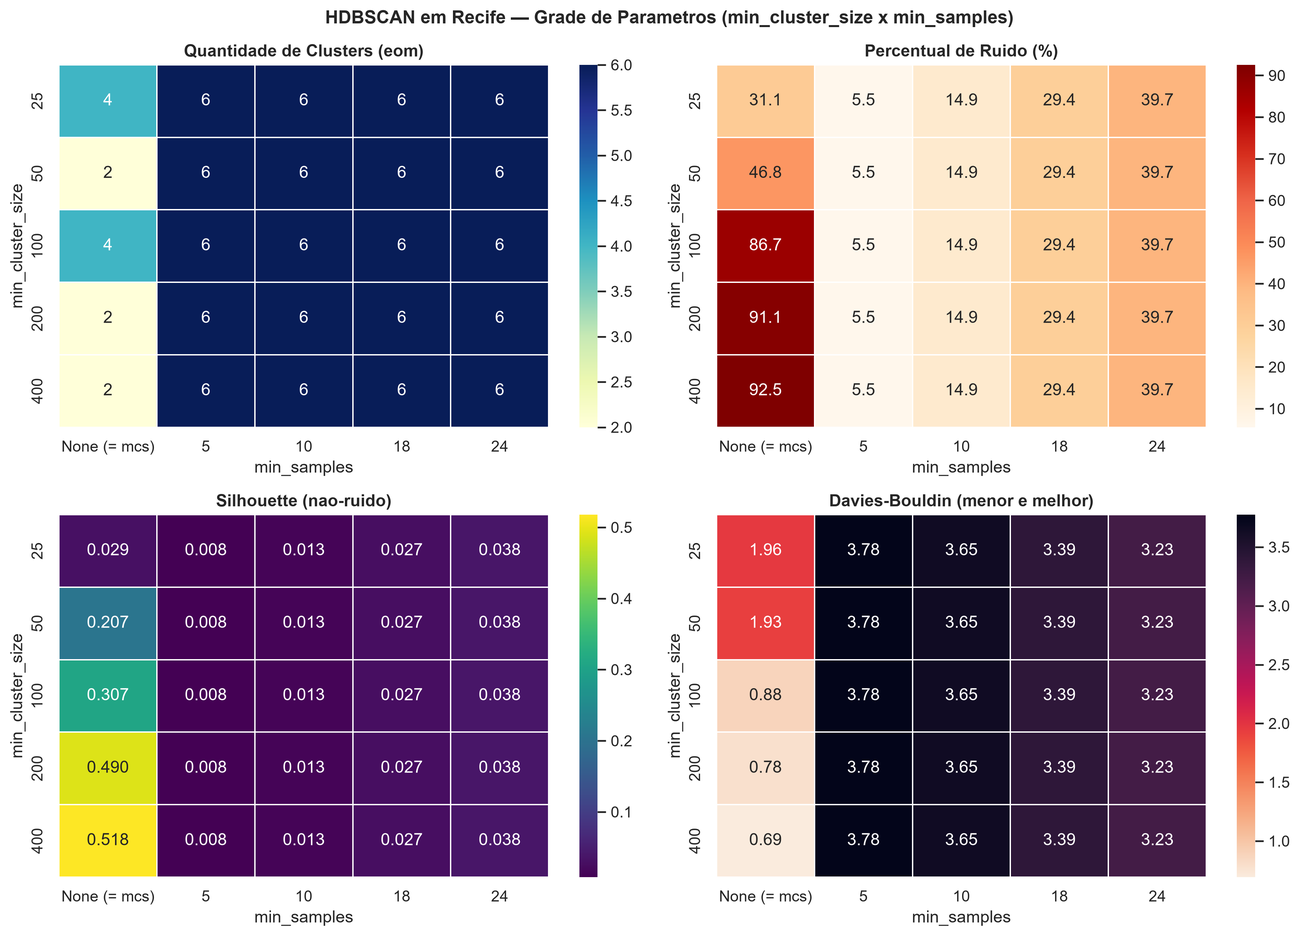

In [3]:
df_grid = pd.read_csv(REPORT_DIR / "metricas_hdbscan.csv")
cols_show = [
    "method", "min_cluster_size", "min_samples_label", "n_clusters",
    "ruido_pct", "cobertura_pct", "silhouette_nao_ruido",
    "davies_bouldin_nao_ruido", "calinski_harabasz_nao_ruido", "prob_media_nao_ruido",
]
print(df_grid[cols_show].to_string(index=False))

img = plt.imread(REPORT_DIR / "figuras" / "grade_parametros_hdbscan.png")
plt.figure(figsize=(13, 9))
plt.imshow(img)
plt.axis("off")
plt.show()


---
## 3. Avaliação de Estabilidade dos Agrupamentos

Para não escolher apenas pelo número de clusters ou por métricas geométricas isoladas, avaliamos a **estabilidade estrutural** dos candidatos viáveis (3 a 8 clusters, ruído ≤ 30%, menor cluster ≥ 1%) de duas formas:
1. **Subamostragem (5 rodadas aleatórias de 80% da base):** mede-se **ARI** (*Adjusted Rand Index*) e **NMI** entre os rótulos gerados na subamostra e os da base completa nos pontos em comum.
2. **Confiança probabilística nativa (`probabilities_`):** mede quão firmemente cada ponto pertence ao seu cluster na hierarquia de densidade condensada.


           config  n_clusters  ruido_pct  cobertura_pct  silhouette_nao_ruido  prob_media_nao_ruido  ari_subamostra_media  ari_subamostra_dp  ari_nao_ruido_media  nmi_subamostra_media  score_hdbscan
 eom mcs=25, ms=5           6     5.5437        94.4563                0.0083                0.9628                0.9672             0.0016                  1.0                0.9496         0.7691
eom mcs=25, ms=10           6    14.9441        85.0559                0.0132                0.9554                0.9079             0.0034                  1.0                0.9039         0.7218
eom mcs=25, ms=18           6    29.4417        70.5583                0.0269                0.9509                0.8115             0.0054                  1.0                0.8463         0.6490


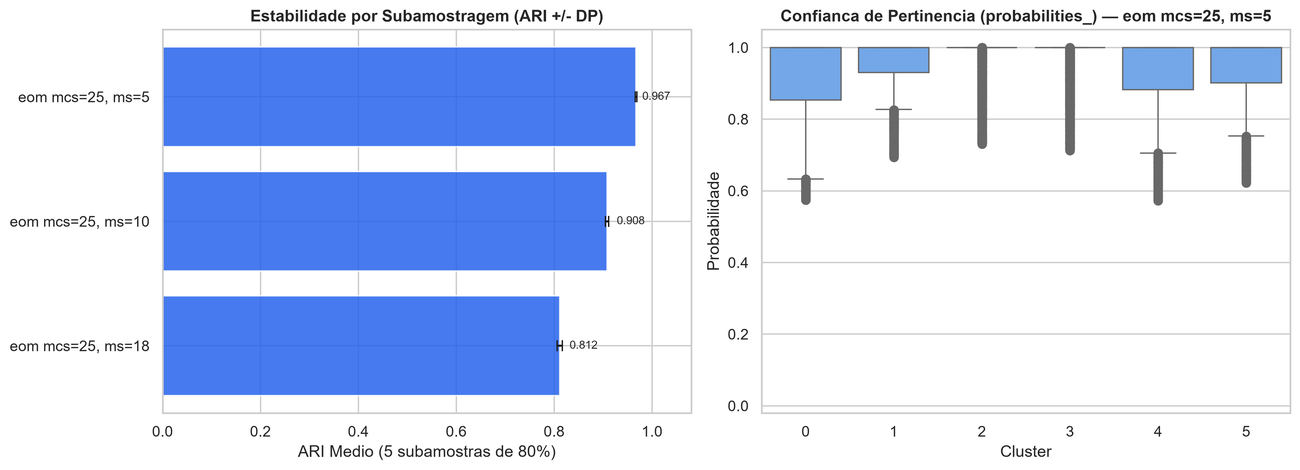

In [4]:
df_estab = pd.read_csv(REPORT_DIR / "estabilidade_hdbscan.csv")
cols_est = [
    "config", "n_clusters", "ruido_pct", "cobertura_pct",
    "silhouette_nao_ruido", "prob_media_nao_ruido",
    "ari_subamostra_media", "ari_subamostra_dp", "ari_nao_ruido_media",
    "nmi_subamostra_media", "score_hdbscan",
]
print(df_estab[cols_est].round(4).to_string(index=False))

img = plt.imread(REPORT_DIR / "figuras" / "estabilidade_hdbscan.png")
plt.figure(figsize=(13, 5))
plt.imshow(img)
plt.axis("off")
plt.show()


---
## 4. Configuração Escolhida e Justificativa

**Configuração escolhida:** `HDBSCAN(min_cluster_size=25, min_samples=5, cluster_selection_method="eom")` *(partição idêntica para `mcs` até 400 com `ms=5`)*.

**Justificativa técnica:**
- **Estabilidade excepcional:** `ARI = 0,967 ± 0,002` nas 5 subamostras de 80% (`ARI = 1,000` entre pontos não-ruído e `NMI = 0,950`), indicando que os 6 regimes são altamente reprodutíveis.
- **Alta cobertura com ruído significativo:** agrupa **94,46%** das horas e isola **5,54%** (`1.850` horas) como ruído — percentual equilibrado (na faixa útil de 2%–12% definida no `dbscan_recife.ipynb`), evitando o descarte extremo (>85%) das configs com `min_samples=None`.
- **Alta confiança de pertinência:** probabilidade média `0,963`, com **92,8%** dos pontos agrupados acima de `0,80`.


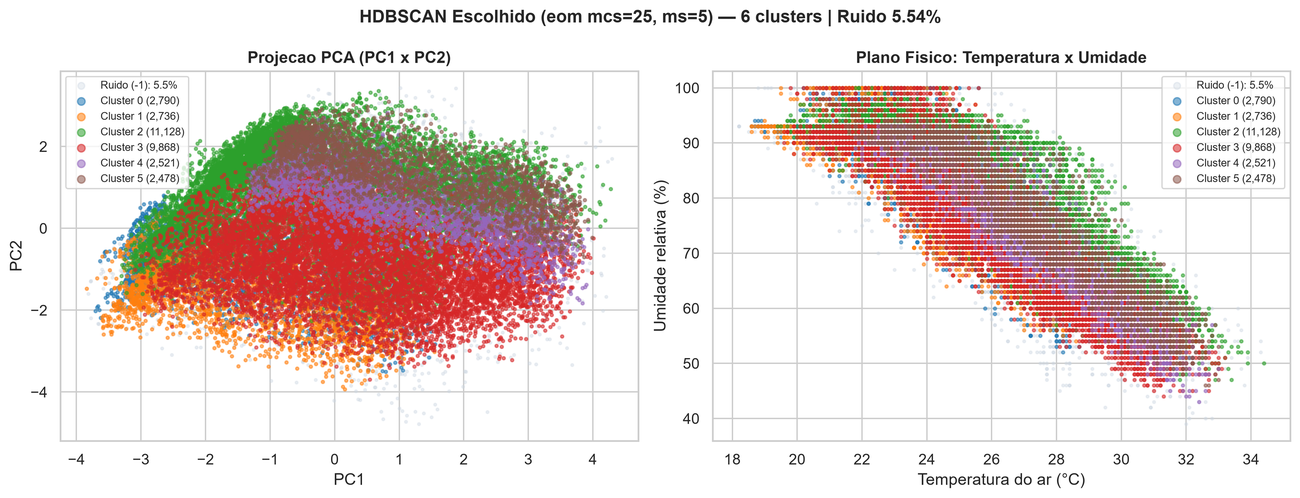

In [5]:
img = plt.imread(REPORT_DIR / "figuras" / "clusters_pca_fisico_hdbscan.png")
plt.figure(figsize=(13.5, 5.5))
plt.imshow(img)
plt.axis("off")
plt.show()


---
## 5. Comparação Direta: HDBSCAN vs. DBSCAN (`dbscan_recife.ipynb`)

Confrontamos a configuração escolhida do **HDBSCAN** (`eom, mcs=25, ms=5`) com as referências do **DBSCAN** obtidas em `Notebooks/dbscan_recife.ipynb` no mesmo espaço `PCA(6)`:
- **DBSCAN C6 (escolhida):** `eps = 0,66`, `min_samples = 24` → 4 clusters, 10,06% de ruído.
- **DBSCAN C1 (aprovada):** `eps = 0,62`, `min_samples = 12` → 4 clusters, 6,28% de ruído.


=== COMPARAÇÃO QUANTITATIVA ===
                 algoritmo               parametros  n_clusters  ruido_pct  cobertura_pct  silhouette_nao_ruido  davies_bouldin_nao_ruido  calinski_harabasz_nao_ruido  ari_vs_dbscan_c6  nmi_vs_dbscan_c6
HDBSCAN (eom mcs=25, ms=5)         eom mcs=25, ms=5           6     5.5437        94.4563                0.0083                    3.7754                    2914.7478            0.6965            0.7384
       DBSCAN_C6_escolhida eps=0.66, min_samples=24           4    10.0566        89.9434                0.0222                    2.1308                    3271.8896            1.0000            1.0000
        DBSCAN_C1_aprovada eps=0.62, min_samples=12           4     6.2809        93.7191                0.0185                    2.1628                    3299.5028            0.9198            0.8796

=== MATRIZ DE CONTINGÊNCIA (Linhas: HDBSCAN | Colunas: DBSCAN C6) ===
           -1     0     1      2     3
HDBSCAN                               
-1     

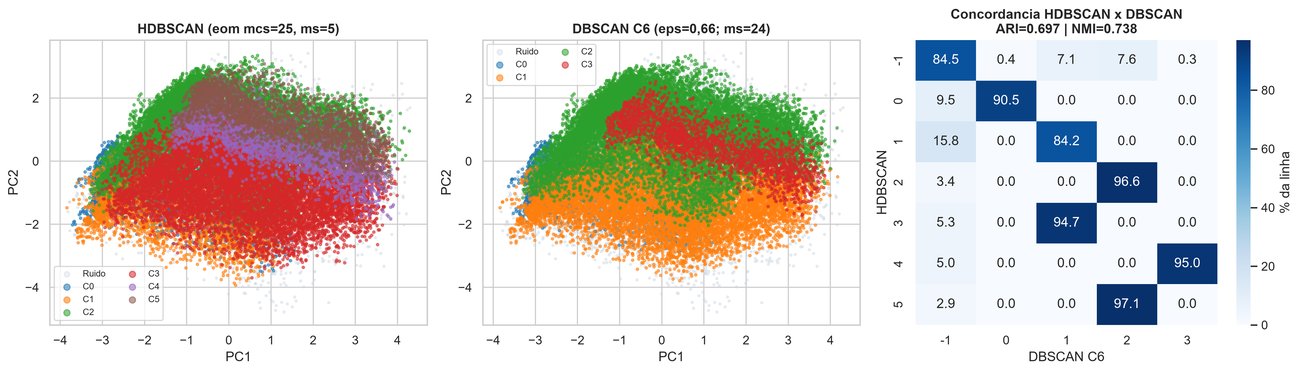

In [6]:
df_comp = pd.read_csv(REPORT_DIR / "comparacao_hdbscan_vs_dbscan.csv")
cols_comp = [
    "algoritmo", "parametros", "n_clusters", "ruido_pct", "cobertura_pct",
    "silhouette_nao_ruido", "davies_bouldin_nao_ruido", "calinski_harabasz_nao_ruido",
    "ari_vs_dbscan_c6", "nmi_vs_dbscan_c6",
]
print("=== COMPARAÇÃO QUANTITATIVA ===")
print(df_comp[cols_comp].round(4).to_string(index=False))

df_ct = pd.read_csv(REPORT_DIR / "contingencia_hdbscan_dbscan.csv", index_col=0)
print("\n=== MATRIZ DE CONTINGÊNCIA (Linhas: HDBSCAN | Colunas: DBSCAN C6) ===")
print(df_ct.to_string())

img = plt.imread(REPORT_DIR / "figuras" / "comparacao_hdbscan_vs_dbscan.png")
plt.figure(figsize=(16, 5))
plt.imshow(img)
plt.axis("off")
plt.show()


### O que o HDBSCAN capturou que o DBSCAN não conseguiu capturar?

A matriz de contingência acima revela um resultado estrutural muito limpo (`ARI = 0,697`, `NMI = 0,738`, com quase zero mistura cruzada):
- **DBSCAN C6 — Cluster 1** (massa grande de ~11,6 mil horas) foi **subdividido pelo HDBSCAN em 2 regimes bem distintos**:
  - **HDBSCAN C1** (`2.736` h): mais frio e úmido (`24,10 °C`, `80,96% UMID`, **18,02% de horas com chuva**);
  - **HDBSCAN C3** (`9.868` h): mais quente e seco (`26,37 °C`, `73,14% UMID`, apenas **5,82% de horas com chuva**).
- **DBSCAN C6 — Cluster 2** (massa grande de ~13,2 mil horas) também foi **subdividido pelo HDBSCAN em 2 regimes distintos**:
  - **HDBSCAN C2** (`11.128` h): ameno e úmido (`25,85 °C`, `81,81% UMID`, **17,91% de horas com chuva**);
  - **HDBSCAN C5** (`2.478` h): quente (`27,41 °C`, `75,10% UMID`, apenas **8,68% de horas com chuva**).
- **Resgate de pontos de ruído:** por não depender de um `eps` global rígido, o HDBSCAN **resgatou 1.793 horas** que o DBSCAN C6 havia descartado como ruído (reduzindo o ruído de `10,06%` para `5,54%`), mantendo apenas os `1.850` eventos realmente atípicos no ruído (`-1`), onde **23,73%** das horas têm chuva!


---
## 6. Densidade Variável, Perfis Meteorológicos e Validação Externa com Chuva

Para verificar empiricamente a **densidade variável**, calculamos a distância mediana ao 15º vizinho (`k-dist 15`) dentro de cada cluster (quanto menor, maior a densidade local) e cruzamos os clusters com a variável externa `precip_mm` (excluída do agrupamento).


=== PERFIL DOS CLUSTERS HDBSCAN (VALIDAÇÃO EXTERNA COM CHUVA) ===
 cluster  registros  participacao_pct  kdist_15_mediana  prob_media  temp_c  temp_orvalho_c  umid_pct  pressao_mb  pct_horas_chuva
      -1       1850             5.544             0.889       0.000  26.247          21.318    75.856    1013.114           23.730
       0       2790             8.361             0.512       0.919  23.970          20.834    83.661    1014.958           23.441
       1       2736             8.199             0.567       0.952  24.102          20.428    80.959    1015.704           18.019
       2      11128            33.346             0.471       0.981  25.846          22.283    81.810    1012.313           17.915
       3       9868            29.571             0.506       0.972  26.375          20.931    73.138    1012.672            5.817
       4       2521             7.554             0.482       0.931  27.294          21.564    72.086    1011.757            6.664
       5       24

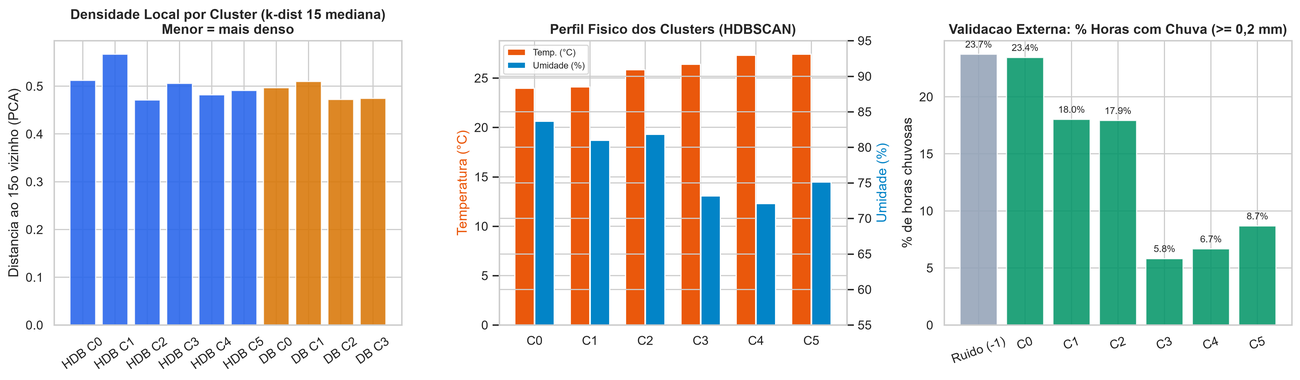

In [7]:
df_dens = pd.read_csv(REPORT_DIR / "densidade_variavel_clusters.csv")
df_hdb_perf = df_dens[df_dens["algoritmo"] == "HDBSCAN"]
cols_p = [
    "cluster", "registros", "participacao_pct", "kdist_15_mediana",
    "prob_media", "temp_c", "temp_orvalho_c", "umid_pct", "pressao_mb", "pct_horas_chuva",
]
print("=== PERFIL DOS CLUSTERS HDBSCAN (VALIDAÇÃO EXTERNA COM CHUVA) ===")
print(df_hdb_perf[cols_p].round(3).to_string(index=False))

img = plt.imread(REPORT_DIR / "figuras" / "perfil_clusters_hdbscan.png")
plt.figure(figsize=(15.5, 5))
plt.imshow(img)
plt.axis("off")
plt.show()


---
## 7. Síntese Final e Reprodutibilidade

- **Densidade variável confirmada:** a razão entre o cluster menos denso (`C1`, `k-dist 15 = 0,567`) e o mais denso (`C2`, `k-dist 15 = 0,471`) foi de **1,20×** no HDBSCAN contra **1,08×** no DBSCAN C6 — evidenciando maior flexibilidade do corte hierárquico.
- **Separação de regimes chuvosos vs. secos (sem usar chuva no treino):** os clusters `C0` (`23,44%` chuva), `C1` (`18,02%`) e `C2` (`17,91%`) concentram regimes úmidos/chuvosos, enquanto `C3` (`5,82%`), `C4` (`6,66%`) e `C5` (`8,68%`) concentram regimes quentes/mais secos. O ruído (`-1`, `5,54%`) captura anomalias meteorológicas com `23,73%` de incidência de chuva.
- **Trade-off HDBSCAN vs. DBSCAN:** o DBSCAN C6 entrega `Silhouette` (`0,0222` vs. `0,0083`) e `Davies-Bouldin` (`2,131` vs. `3,775`) ligeiramente melhores porque descarta mais pontos de transição como ruído (`10,06%`) e mantém 2 massas agregadas; em contrapartida, o **HDBSCAN (`eom, mcs=25, ms=5`)** elimina a escolha manual de `eps`, reduz o ruído pela metade (`5,54%`), demonstra estabilidade muito alta (`ARI = 0,967`) e desdobra as duas massas grandes em regimes chuvosos e secos fisicamente interpretáveis.
- **Reprodutibilidade:** todos os resultados, tabelas e figuras são regeneráveis via `python ml/experimento_hdbscan_recife.py` e ficam salvos em `reports/hdbscan_recife/`.
